# Pronostico

Predecir la inflacion del mes que viene de cada rubro en cada region, y ver si un modelo le gana a lo mas simple, que es suponer que el mes que viene va a ser igual a este.

Codigo en `src/monitor/pronostico.py`.

- **Cuando se pronostica.** Cuando el INDEC publica el mayorista del mes anterior, cerca del 19. Para ese momento se sabe: el IPC y el mayorista de T-1, la inflacion general, el REM de fines de T-1 y el dolar de la primera quincena de T. Todos los features salen de eso y nada mas.
- **Datos de afuera del INDEC.** Del BCRA: el dolar mayorista y la mediana del REM (lo que esperan los analistas). Sin eso, un tercio del error era un shock que pegaba a todos los rubros a la vez y ninguna variable del rubro lo podia ver.
- **Modelos.** Tres de referencia (naive = repetir el ultimo mes, promedio de 3 meses, mismo mes del anio anterior), una regresion lineal por serie (ARX) y un LightGBM global para las 114 series juntas. El pronostico final es el promedio de LightGBM y ARX.
- **Validacion.** Origen movil: para cada uno de los ultimos 36 meses se entrena solo con lo anterior y se predice ese mes. Las decisiones (que variables, que modelo) las tome mirando solo nov-23 a oct-25. El ultimo anio quedo guardado como prueba final y se miro una sola vez.
- **Ojo:** el backtest usa los datos ya revisados por el INDEC. En tiempo real se tenia el provisorio. Por eso cada pronostico nuevo queda en `data/resultados/registro_pronosticos.csv` sin pisarse, para medir el error real de aca en adelante.

In [1]:
import os

import lightgbm as lgb
import matplotlib.pyplot as plt
import pandas as pd

from monitor import analisis as a
from monitor import pronostico as p

a.estilo()
con = a.conectar()
nombres = a.nombres_rubros(con)
panel = p.datos(con)

pred = p.calibrar(p.backtest(panel, meses=48, procesos=os.cpu_count()))
pred = pred[pred.ajuste.notna() & (pred.fecha >= sorted(pred.fecha.unique())[-36])].copy()
meses = sorted(pred.fecha.unique())
pred["tramo"] = (pred.fecha >= meses[-12]).map({False: "desarrollo", True: "prueba final"})
pred["anio"] = pred.fecha.dt.year
print(f"{len(pred)} pronosticos de {meses[0]:%m-%Y} a {meses[-1]:%m-%Y}")

4104 pronosticos de 11-2023 a 10-2026


## 1. Quien gana

In [2]:
tabla = p.metricas(pred, p.escala_mase(panel, pred.fecha.min()))
tabla.round(3)

,mae_pp,rmse_pp,mase,vs_naive,cobertura_80_cruda,cobertura_80_calibrada
modelo,,,,,,
naive,2.884,5.553,1.256,1.000,NaN,NaN
media3,3.125,5.672,1.441,1.083,NaN,NaN
estacional,5.822,9.360,2.892,2.019,NaN,NaN
arx,2.504,4.530,1.118,0.868,NaN,NaN
lgbm,2.318,4.481,1.035,0.804,NaN,NaN
combinado,2.238,4.180,0.979,0.776,0.659,0.808


- `mae_pp` es el error medio en puntos porcentuales de inflacion mensual. El combinado queda en 2.24 contra 2.88 del naive: un 22% menos.
- `vs_naive` es el error relativo al naive, debajo de 1 es mejor.
- El MASE da arriba de 1 para casi todos porque se escala con el error de la historia previa, que fue mas tranquila que el periodo de prueba (arranca justo antes de diciembre de 2023). Por eso miro `vs_naive`.
- El mismo mes del anio anterior es el peor: con una inflacion que cambia tanto de un anio a otro no sirve.

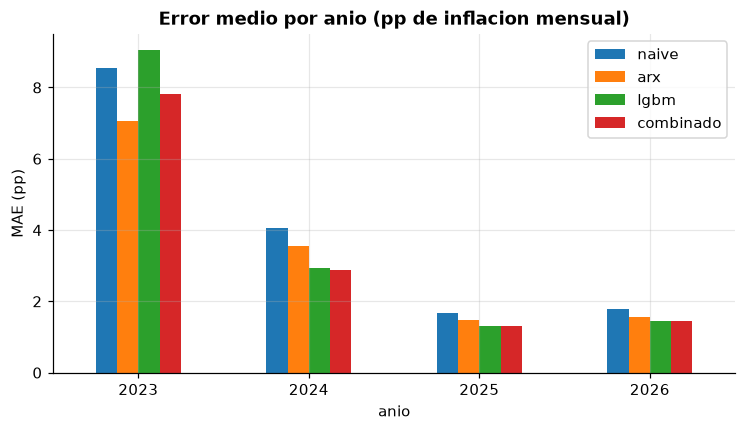

,naive,arx,lgbm,combinado
anio,,,,
2023,8.55,7.05,9.05,7.82
2024,4.07,3.57,2.94,2.88
2025,1.68,1.47,1.30,1.31
2026,1.78,1.56,1.46,1.46


In [3]:
modelos = ["naive", "arx", "lgbm", "combinado"]
por_anio = pred.groupby("anio").apply(
    lambda d: pd.Series({m: 100 * (d.y - d[m]).abs().mean() for m in modelos}), include_groups=False
)
ax = por_anio.plot.bar(figsize=(8, 4), rot=0)
ax.set_title("Error medio por anio (pp de inflacion mensual)")
ax.set_ylabel("MAE (pp)")
plt.show()
por_anio.round(2)

2023 son solo noviembre y diciembre, con la devaluacion de diciembre. Ahi se ve por que combinar: LightGBM erra 9.1 y el ARX 7.1. Un arbol no puede pronosticar mas alla de lo que vio al entrenar, y un salto del dolar como ese no lo habia visto nunca; la regresion lineal si extrapola. Desde 2024 LightGBM y el combinado andan parecido y los dos le ganan al naive por mas de un 15% todos los anios.

## 2. Que aporto el BCRA

Mismo LightGBM sin las tres variables del BCRA, para comparar.

In [4]:
con_y = panel[panel.y.notna()]
sin_bcra = [f for f in p.FEATURES if f not in p.FEATURES_BCRA]
partes = []
for mes in meses:
    tr, te = con_y[con_y.fecha < mes], con_y[con_y.fecha == mes]
    m = lgb.train(
        p.PARAMS, lgb.Dataset(tr[sin_bcra], tr.y, categorical_feature=p.CATEGORICAS), p.ARBOLES
    )
    partes.append(te[["par_id", "region", "fecha"]].assign(sin_bcra=m.predict(te[sin_bcra])))
pred = pred.merge(pd.concat(partes), on=["par_id", "region", "fecha"])

comparar = ["naive", "sin_bcra", "lgbm", "combinado"]
pred.groupby("tramo").apply(
    lambda d: pd.Series({m: 100 * (d.y - d[m]).abs().mean() for m in comparar}),
    include_groups=False,
).round(3)

,naive,sin_bcra,lgbm,combinado
tramo,,,,
desarrollo,3.465,3.020,2.762,2.641
prueba final,1.723,1.417,1.431,1.432


- **Desarrollo (nov-23 a oct-25):** con el BCRA el error baja de 3.02 a 2.76, y el combinado a 2.64. Es la etapa con saltos del dolar.
- **Prueba final (nov-25 a oct-26):** empatan (1.42 sin BCRA, 1.43 con). En un anio calmo el dolar casi no se mueve y no tiene nada para aportar.

O sea: el BCRA no mejora los meses tranquilos, pero tampoco los empeora, y paga cuando hay un shock. Para un monitor de precios en Argentina es un seguro que vale la pena. Lo dejo dicho asi porque la prueba final no muestra la mejora: la evidencia sale del tramo de desarrollo, que es donde tome las decisiones, asi que puede estar un poco inflada.

## 3. Es una mejora de verdad?

Test de Diebold-Mariano: compara los errores de dos modelos mes a mes. Promedio el error de todas las series de cada mes para no contar 114 veces el mismo shock.

In [5]:
pd.DataFrame(
    [
        p.diebold_mariano(pred, "combinado", b)
        for b in ["naive", "media3", "arx", "sin_bcra", "lgbm"]
    ]
).round(4)

,a,b,dif_mae_pp,estadistico,p_valor
0,combinado,naive,-0.6465,-3.5969,0.0010
1,combinado,media3,-0.8869,-2.9622,0.0055
2,combinado,arx,-0.2658,-2.3364,0.0253
3,combinado,sin_bcra,-0.2478,-2.2368,0.0318
4,combinado,lgbm,-0.0803,-1.0890,0.2836


Contra el naive, el promedio de 3 meses, el ARX y el LightGBM sin BCRA, el combinado gana con p < 0.05. Contra LightGBM con BCRA no hay diferencia significativa (p = 0.28): combinar no mejora el promedio, lo que hace es cubrir los meses de shock.

## 4. Intervalos

Ademas del numero, el modelo da un rango donde deberia caer el dato el 80% de las veces. Sale de los cuantiles 10 y 90 de LightGBM, corridos para que queden alrededor del pronostico combinado. Los cuantiles solos quedan cortos, asi que los calibro con conformal: cada mes ensancho el intervalo de cada rubro segun cuanto fallo ese rubro en los 12 meses anteriores. Por rubro y no uno para todos porque si no verduras cubria 67% y pan 88%.

In [6]:
cobertura = pred.groupby("anio").apply(
    lambda d: pd.Series(
        {
            "cruda": d.y.between(d.lgbm_q10, d.lgbm_q90).mean(),
            "calibrada": d.y.between(d.lgbm_inf, d.lgbm_sup).mean(),
            "ancho_pp": 100 * (d.lgbm_sup - d.lgbm_inf).mean(),
        }
    ),
    include_groups=False,
)
por_rubro = pred.y.between(pred.lgbm_inf, pred.lgbm_sup).groupby(pred.par_id).mean()
print(f"cobertura por rubro: de {por_rubro.min():.0%} a {por_rubro.max():.0%}")
cobertura.round(2)

cobertura por rubro: de 76% a 84%


,cruda,calibrada,ancho_pp
anio,,,
2023,0.27,0.39,9.43
2024,0.66,0.89,12.46
2025,0.70,0.81,5.14
2026,0.68,0.79,4.58


La cobertura total queda en 81% y por rubro entre 76% y 84%. En 2024 sobra (89%) porque la calibracion arrastra la devaluacion y los intervalos quedan anchos; en 2025-2026 anda en 80%. Diciembre de 2023 cubre solo un 37%: no hay historia con la que calibrar un salto asi.

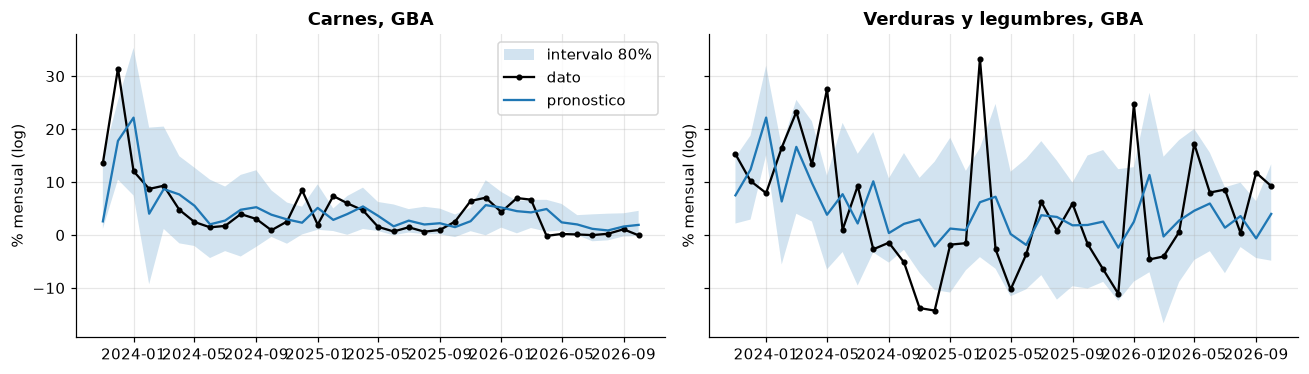

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, rubro in zip(axes, ["carnes", "verduras"], strict=True):
    s = pred[(pred.par_id == rubro) & (pred.region == "GBA")].set_index("fecha")
    ax.fill_between(s.index, 100 * s.lgbm_inf, 100 * s.lgbm_sup, alpha=0.2, label="intervalo 80%")
    ax.plot(s.index, 100 * s.y, "k.-", label="dato")
    ax.plot(s.index, 100 * s.combinado, label="pronostico")
    ax.set_title(f"{nombres[rubro]}, GBA")
    ax.set_ylabel("% mensual (log)")
axes[0].legend()
plt.tight_layout()
plt.show()

En carnes el intervalo se achica a medida que baja la inflacion y el dato casi siempre cae adentro. Verduras tiene su propio ancho, mucho mayor, pero igual los saltos mas grandes quedan afuera: son shocks de oferta (clima, cosecha) que no se ven en ningun dato del mes anterior.

## 5. Que mira el modelo

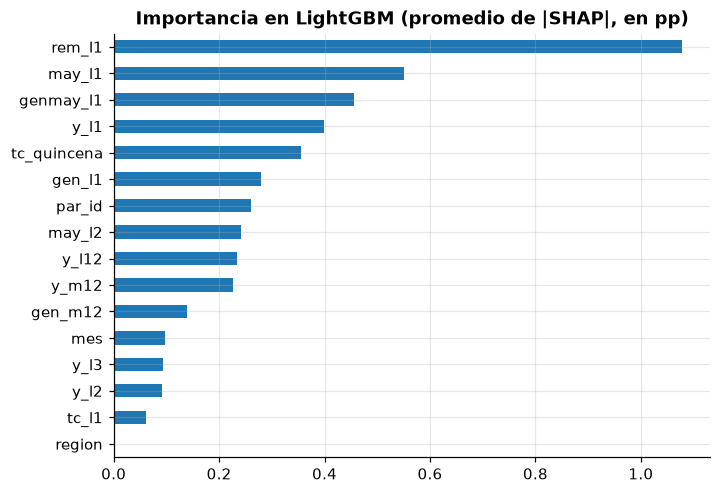

In [8]:
imp = p.importancia(panel)
ax = imp.plot.barh(figsize=(7, 5))
ax.set_title("Importancia en LightGBM (promedio de |SHAP|, en pp)")
plt.show()

Lo que mas pesa ahora es el **REM**. Lo que esperan los analistas probablemente resume cosas que el modelo no ve (tarifas anunciadas, acuerdos de precios), y ademas marca el nivel de inflacion de cada etapa. Despues viene el **mayorista del mes anterior**, el del rubro y el general, que encaja con el modelo de traslado: la suba mayorista llega a la gondola en el mismo mes o en el siguiente. El dolar de la primera quincena aparece arriba de la inflacion general del mes anterior. La region casi no aporta, igual que en el traslado.

Esto es importancia para predecir, no causalidad.

## 6. El mes que viene

In [9]:
ultimos = pred[pred.fecha >= meses[-12]]
proximo = p.pronosticar_proximo(panel, p.ajustes(ultimos))
print(f"pronostico para {proximo.fecha.iloc[0]:%m-%Y}, en % mensual")
(
    proximo[proximo.region == "GBA"]
    .set_index("par_id")
    .rename(index=nombres)[["pronostico", "inf", "sup"]]
    .sort_values("pronostico")
    .round(1)
)

pronostico para 11-2026, en % mensual


,pronostico,inf,sup
par_id,,,
Verduras y legumbres,-0.4,-7.4,11.6
Lacteos y huevos,1.1,0.7,2.3
Prendas de vestir,1.5,-0.4,2.8
Equipamiento del hogar,1.7,0.9,2.8
Calzado,1.7,0.1,3.2
Azucar y golosinas,1.7,0.9,2.9
Bebidas alcoholicas,1.8,0.3,2.5
Aceites y grasas,1.9,0.3,3.2
Cuidado personal,1.9,0.8,3.2


Se ve la estacionalidad del EDA: verduras para abajo en noviembre y frutas para arriba. Los intervalos mas anchos son los de verduras, frutas, energia, combustibles y carnes; los mas angostos, pan, medicamentos y lacteos.

## Resumen

- El combinado (LightGBM + ARX) le gana a repetir el ultimo mes por un 22% en los 36 meses, y la diferencia es significativa.
- Sumar el dolar y el REM del BCRA mejora los periodos con shock y no cambia nada en los tranquilos.
- Los intervalos cubren lo que tienen que cubrir (81% para un 80%), parejo entre rubros.
- Lo que mas ayuda a predecir es el REM, despues el mayorista del mes anterior.

Limites: un solo mes de horizonte, datos ya revisados en el backtest y una ventaja que se apoya en pocos meses de shock.